In [121]:
import pandas as pd
import numpy as np
import re
import string
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [122]:
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [123]:
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [124]:
df = pd.read_csv("../data/resume_dataset.csv")

In [125]:
df.head()

,resume,category
0,Professional Summary: 6 years of experience as...,Health and fitness
1,Career Overview: Experienced SAP Developer wit...,SAP Developer
2,Profile: Results-oriented Data Integration Dev...,ETL Developer
3,Profile: Results-oriented Operations Executive...,Operations Manager
4,Profile: Results-oriented Cybersecurity Engine...,Network Security Engineer


In [126]:
df.shape

(1500, 2)

In [127]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   resume    1500 non-null   str  
 1   category  1500 non-null   str  
dtypes: str(2)
memory usage: 1.5 MB


In [128]:
df.isnull().sum()

resume      0
category    0
dtype: int64

In [129]:
df["category"].value_counts()

category
Health and fitness           60
SAP Developer                60
ETL Developer                60
Operations Manager           60
Network Security Engineer    60
Advocate                     60
Hadoop                       60
Arts                         60
Testing                      60
Business Analyst             60
HR                           60
Electrical Engineering       60
Python Developer             60
Sales                        60
DotNet Developer             60
Civil Engineer               60
Data Science                 60
Blockchain                   60
Web Designing                60
Automation Testing           60
Database                     60
PMO                          60
Java Developer               60
DevOps Engineer              60
Mechanical Engineer          60
Name: count, dtype: int64

In [130]:
df.duplicated().sum()

np.int64(0)

In [131]:
df = df.drop_duplicates()

In [132]:
df = df.reset_index(drop=True)

In [133]:
df.isnull().sum()

resume      0
category    0
dtype: int64

In [134]:
df = df.dropna(subset=["resume", "category"])

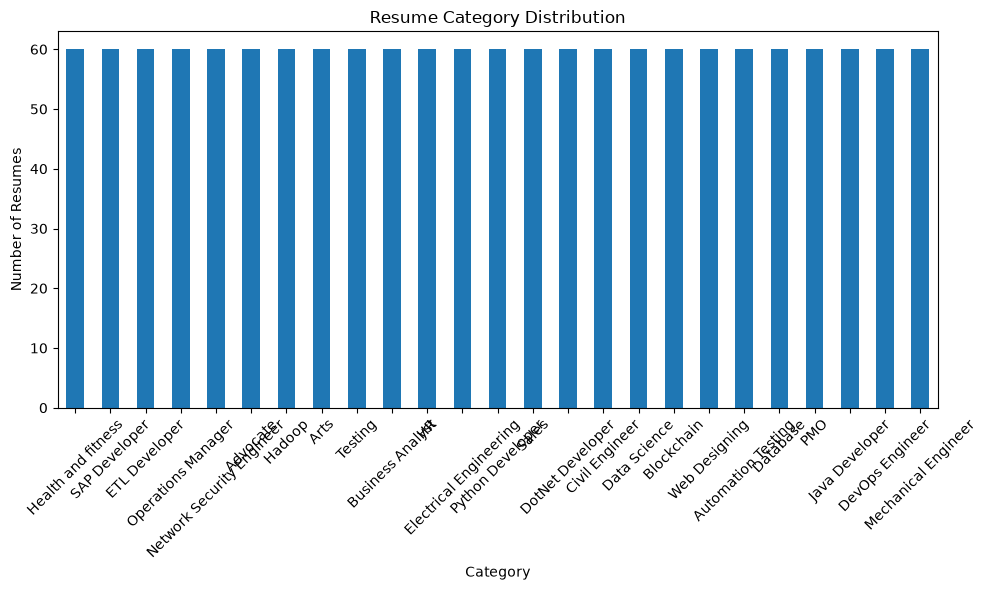

In [135]:
plt.figure(figsize=(10, 6))

df["category"].value_counts().plot(kind="bar")

plt.title("Resume Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [136]:
stop_words = set(stopwords.words("english"))

lemmatizer = WordNetLemmatizer()

In [137]:
def clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)

In [138]:
sample = df["resume"].iloc[0]

print("Original:")
print(sample)

print("\nCleaned:")
print(clean_text(sample))

Original:
Professional Summary: 6 years of experience as a Fitness Trainer. Strong background in exercise programming, mobility training, weight management, wellness education. Skilled in fitness assessment, workout planning, exercise programming, mobility training, site supervision, body composition, cardio conditioning, client coaching, weight management. Experience includes designed workout plans and tracked client progress. Project Experience: Worked on client transformation program, where responsibilities included planning, implementation, testing, documentation, and stakeholder coordination. Also contributed to group fitness plan. Tools and Technologies: strength training, cardio conditioning, weight management, injury prevention, fitness assessment, workout planning, wellness education. Education: Master of Science. Strengths include documentation, problem solving, time management. Comfortable working in Agile teams and delivering reliable outcomes. Key Contributions: Guided str

In [139]:
df["clean_resume"] = df["resume"].apply(clean_text)

In [140]:
df["clean_resume"] = df["resume"].apply(clean_text)

In [141]:
df["clean_resume"].str.len().describe()

count    1500.000000
mean      930.618667
std        95.386003
min       729.000000
25%       853.000000
50%       932.500000
75%      1000.000000
max      1191.000000
Name: clean_resume, dtype: float64

In [142]:
X = df["clean_resume"]
y = df["category"]

In [143]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [144]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

In [145]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [146]:
X_test_tfidf = tfidf.transform(X_test)

In [147]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(1200, 10000)
(300, 10000)


In [148]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)

In [149]:
lr_model = LogisticRegression(
    max_iter=2000
)

lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)

In [150]:
svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

In [151]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

rf_pred = rf_model.predict(X_test_tfidf)

In [152]:
def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

In [153]:
results = []

results.append(
    evaluate_model(
        "Naive Bayes",
        y_test,
        nb_pred
    )
)

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        lr_pred
    )
)

results.append(
    evaluate_model(
        "SVM",
        y_test,
        svm_pred
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)

In [154]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0
2,SVM,1.0,1.0,1.0,1.0
3,Random Forest,1.0,1.0,1.0,1.0


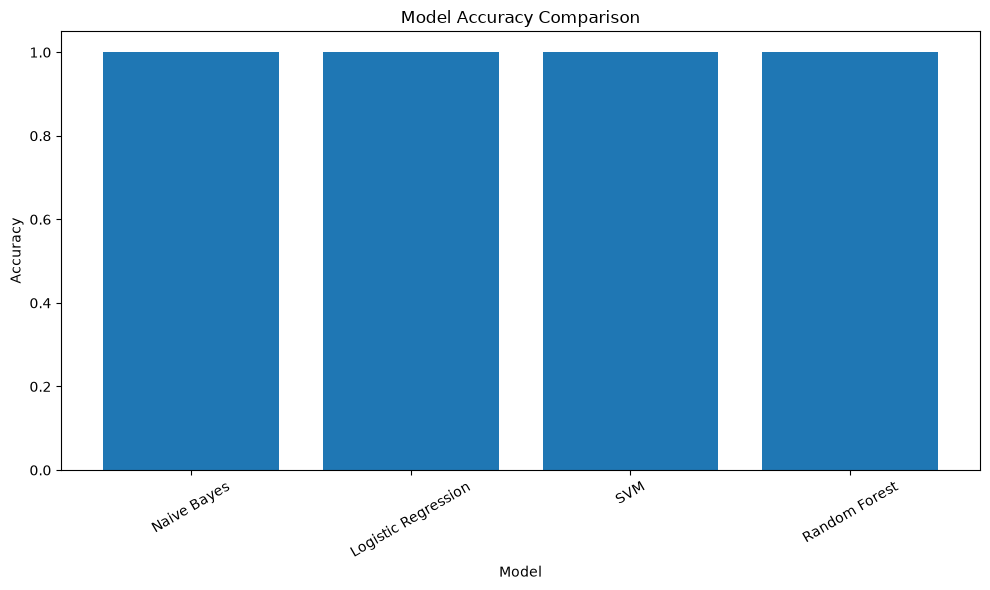

In [155]:
plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "../results/model_comparison.png"
)

plt.show()

In [156]:
print("Naive Bayes")
print(classification_report(y_test, nb_pred))

Naive Bayes
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00        12
                     Arts       1.00      1.00      1.00        12
       Automation Testing       1.00      1.00      1.00        12
               Blockchain       1.00      1.00      1.00        12
         Business Analyst       1.00      1.00      1.00        12
           Civil Engineer       1.00      1.00      1.00        12
             Data Science       1.00      1.00      1.00        12
                 Database       1.00      1.00      1.00        12
          DevOps Engineer       1.00      1.00      1.00        12
         DotNet Developer       1.00      1.00      1.00        12
            ETL Developer       1.00      1.00      1.00        12
   Electrical Engineering       1.00      1.00      1.00        12
                       HR       1.00      1.00      1.00        12
                   Hadoop       1.00      1.00   

In [157]:
print("Logistic Regression")
print(classification_report(y_test, lr_pred))

Logistic Regression
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00        12
                     Arts       1.00      1.00      1.00        12
       Automation Testing       1.00      1.00      1.00        12
               Blockchain       1.00      1.00      1.00        12
         Business Analyst       1.00      1.00      1.00        12
           Civil Engineer       1.00      1.00      1.00        12
             Data Science       1.00      1.00      1.00        12
                 Database       1.00      1.00      1.00        12
          DevOps Engineer       1.00      1.00      1.00        12
         DotNet Developer       1.00      1.00      1.00        12
            ETL Developer       1.00      1.00      1.00        12
   Electrical Engineering       1.00      1.00      1.00        12
                       HR       1.00      1.00      1.00        12
                   Hadoop       1.00     

In [158]:
print("SVM")
print(classification_report(y_test, svm_pred))

SVM
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00        12
                     Arts       1.00      1.00      1.00        12
       Automation Testing       1.00      1.00      1.00        12
               Blockchain       1.00      1.00      1.00        12
         Business Analyst       1.00      1.00      1.00        12
           Civil Engineer       1.00      1.00      1.00        12
             Data Science       1.00      1.00      1.00        12
                 Database       1.00      1.00      1.00        12
          DevOps Engineer       1.00      1.00      1.00        12
         DotNet Developer       1.00      1.00      1.00        12
            ETL Developer       1.00      1.00      1.00        12
   Electrical Engineering       1.00      1.00      1.00        12
                       HR       1.00      1.00      1.00        12
                   Hadoop       1.00      1.00      1.00 

In [159]:
print("Random Forest")
print(classification_report(y_test, rf_pred))

Random Forest
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00        12
                     Arts       1.00      1.00      1.00        12
       Automation Testing       1.00      1.00      1.00        12
               Blockchain       1.00      1.00      1.00        12
         Business Analyst       1.00      1.00      1.00        12
           Civil Engineer       1.00      1.00      1.00        12
             Data Science       1.00      1.00      1.00        12
                 Database       1.00      1.00      1.00        12
          DevOps Engineer       1.00      1.00      1.00        12
         DotNet Developer       1.00      1.00      1.00        12
            ETL Developer       1.00      1.00      1.00        12
   Electrical Engineering       1.00      1.00      1.00        12
                       HR       1.00      1.00      1.00        12
                   Hadoop       1.00      1.00 

In [160]:
cm = confusion_matrix(
    y_test,
    svm_pred
)

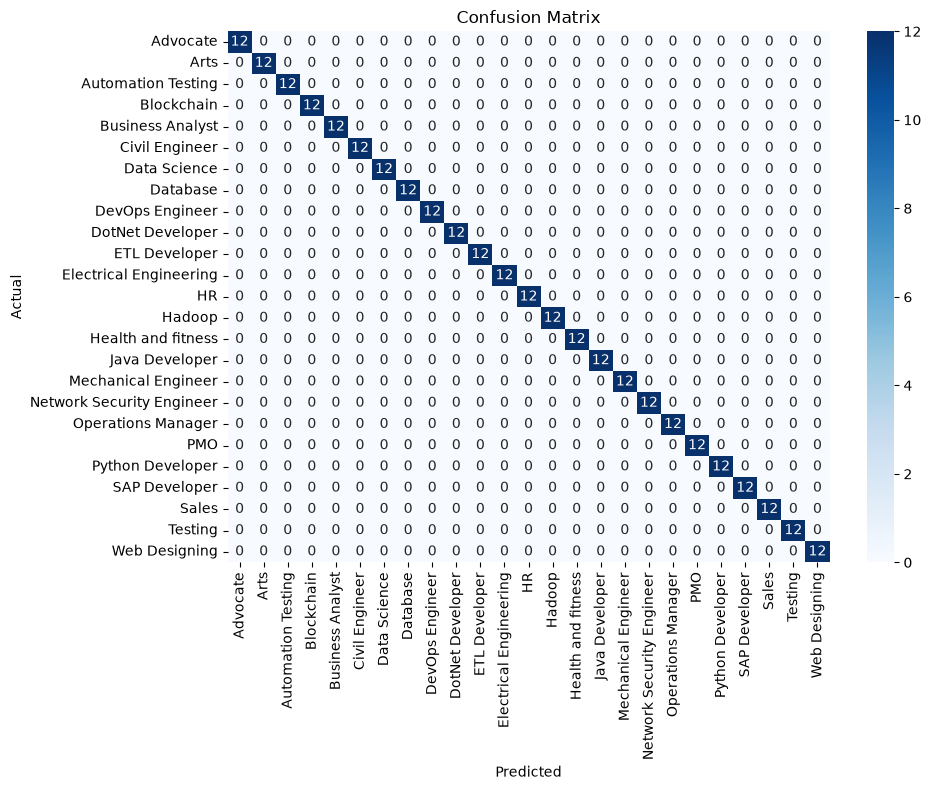

In [161]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y_test.unique()),
    yticklabels=sorted(y_test.unique())
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    "../results/confusion_matrix.png"
)

plt.show()

In [162]:
voting_model = VotingClassifier(
    estimators=[
        ("nb", nb_model),
        ("lr", lr_model),
        ("svm", svm_model),
        ("rf", rf_model)
    ],
    voting="hard"
)

In [163]:
voting_model.fit(
    X_train_tfidf,
    y_train
)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('nb', ...), ('lr', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](25,)","['Advocate','Arts','Automation Testing',...,'Sales','Testing', 'Web Designing']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[MultinomialNB(), LogisticRegre...max_iter=2000), LinearSVC(), RandomForestC...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,10000


In [164]:
voting_pred = voting_model.predict(
    X_test_tfidf
)

In [165]:
ensemble_result = evaluate_model(
    "Voting Ensemble",
    y_test,
    voting_pred
)

ensemble_result

{'Model': 'Voting Ensemble',
 'Accuracy': 1.0,
 'Precision': 1.0,
 'Recall': 1.0,
 'F1 Score': 1.0}

In [166]:
results.append(ensemble_result)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0
2,SVM,1.0,1.0,1.0,1.0
3,Random Forest,1.0,1.0,1.0,1.0
4,Voting Ensemble,1.0,1.0,1.0,1.0


In [167]:
voting="soft"

In [168]:
cm = confusion_matrix(
    y_test,
    voting_pred
)

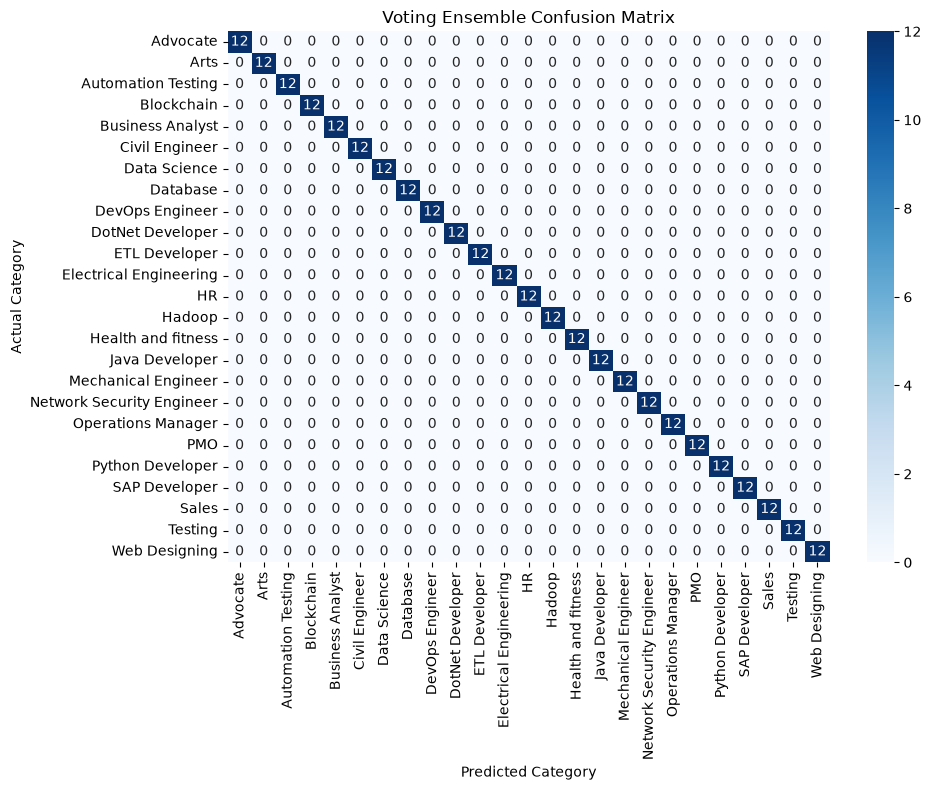

In [169]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y_test.unique()),
    yticklabels=sorted(y_test.unique())
)

plt.title("Voting Ensemble Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    "../results/confusion_matrix.png"
)

plt.show()

In [170]:
model_package = {
    "tfidf": tfidf,
    "naive_bayes": nb_model,
    "logistic_regression": lr_model,
    "svm": svm_model,
    "random_forest": rf_model,
    "voting_ensemble": voting_model,
    "categories": sorted(y.unique())
}

In [171]:
model_package = {
    "tfidf": tfidf,
    "naive_bayes": nb_model,
    "logistic_regression": lr_model,
    "svm": svm_model,
    "random_forest": rf_model,
    "voting_ensemble": voting_model,
    "categories": sorted(y.unique())
}

In [172]:
print(model_package.keys())

dict_keys(['tfidf', 'naive_bayes', 'logistic_regression', 'svm', 'random_forest', 'voting_ensemble', 'categories'])


In [173]:
import joblib

model_path = "../models/resume_model.pkl"

joblib.dump(
    model_package,
    model_path
)

print("Model saved successfully!")

Model saved successfully!


In [174]:
import os

print(
    "Model size:",
    os.path.getsize(model_path),
    "bytes"
)

Model size: 30429222 bytes


In [175]:
loaded_model = joblib.load(
    "../models/resume_model.pkl"
)

print("Model loaded successfully!")
print(loaded_model.keys())

Model loaded successfully!
dict_keys(['tfidf', 'naive_bayes', 'logistic_regression', 'svm', 'random_forest', 'voting_ensemble', 'categories'])


In [177]:
print("Dataset size:", len(df))
print("\nCategory counts:")
print(df["category"].value_counts())

print("\nNumber of categories:", df["category"].nunique())

print("\nAccuracy:")
print("Naive Bayes:", accuracy_score(y_test, nb_pred))
print("Logistic Regression:", accuracy_score(y_test, lr_pred))
print("SVM:", accuracy_score(y_test, svm_pred))
print("Random Forest:", accuracy_score(y_test, rf_pred))
print("Voting Ensemble:", accuracy_score(y_test, voting_pred))

Dataset size: 1500

Category counts:
category
Health and fitness           60
SAP Developer                60
ETL Developer                60
Operations Manager           60
Network Security Engineer    60
Advocate                     60
Hadoop                       60
Arts                         60
Testing                      60
Business Analyst             60
HR                           60
Electrical Engineering       60
Python Developer             60
Sales                        60
DotNet Developer             60
Civil Engineer               60
Data Science                 60
Blockchain                   60
Web Designing                60
Automation Testing           60
Database                     60
PMO                          60
Java Developer               60
DevOps Engineer              60
Mechanical Engineer          60
Name: count, dtype: int64

Number of categories: 25

Accuracy:
Naive Bayes: 1.0
Logistic Regression: 1.0
SVM: 1.0
Random Forest: 1.0
Voting Ensemble: 1.0
